# CS5100 Data Analysis Lab - Week 4: Decision trees and neural networks

## Learning Outcomes

- Regression Decision Trees
- Classification Neural Networks

For this lab, you need to import NumPy, Matplotlib, Pandas, Scikit-Learn, and PyTorch

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import sklearn
np.random.seed(12345)

## Fitting a regression tree

Fit a regression tree to the Diabetes dataset using the ```sklearn``` library.
The dataset, available from ``sklearn.datasets``, contains data from 442 diabetic patients. 
There are ten variables: age, sex, body mass index, average blood pressure, and six blood serum measurements. 
The goal is to predict a quantitative measure of disease progression. 
For more info about the dataset, run ```help(load_diabetes)``` or ```?load_diabetes```.

In [ ]:
from sklearn.datasets import load_diabetes
diabetes = load_diabetes(as_frame=True)
X_pd = diabetes.data
y_pd = diabetes.target
print(f"X_pd.shape = {X_pd.shape}")
print(f"y_pd.shape = {y_pd.shape}")
print(f"[x for x in diabetes.data.columns] = {[x for x in diabetes.data.columns]}")


Print the response against each predictor to understand the data

In [ ]:
ix = 8
plt.plot(diabetes.data[diabetes.data.columns[ix]], diabetes.target, 'o')
plt.xlabel(diabetes.data.columns[ix])
plt.ylabel('target')
plt.show()

Create a training, validation, and test sets. Normalise the features for stability.

In [ ]:
def split_dataset(D, ratio):
    X, y = D
    reshuffle = np.random.choice(len(X), len(X), replace=False)
    nratio = [int(np.floor(r * len(X))) for r in ratio]
    Xtrain, ytrain = [np.array([s[i] for i in reshuffle[:nratio[0]]]) for s in D]
    Xval, yval = [np.array([s[i] for i in reshuffle[nratio[0]:nratio[0] + nratio[1]]]) for s in D]
    Xtest, ytest = [np.array([s[i] for i in reshuffle[nratio[0] + nratio[1]:]]) for s in D]
    return (Xtrain, ytrain), (Xval, yval), (Xtest, ytest)

def normalise_features(X, y):
    return (X - np.mean(X, axis=0))/(1e-4+np.std(X, axis=0)), y

datasets = split_dataset((X_pd.to_numpy(), y_pd.to_numpy()), (.6, .2))
datasets = [normalise_features(z[0], z[1]) for z in datasets]
data_names = ['train', 'validation', 'test']
for idata in range(len(data_names)):
    X, y = datasets[idata]
    print(f"{data_names[idata]}: X.shape = {X.shape}, y.shape = {y.shape}")


Load and use `DecisionTreeRegressor` to build the tree.

In [ ]:
from sklearn.tree import plot_tree
from sklearn.tree import DecisionTreeRegressor

train, val, test = datasets
dt_diabetes = DecisionTreeRegressor(max_depth=10)
dt_diabetes.fit(train[0], train[1])
extras = plot_tree(dt_diabetes)
print(f"extras[0] = {extras[1]}")

Evaluate the performance of the tree using the MSE, the R^2, and the correlations between the predictions, $\hat y_i = f(x_i)$, and the true labels, $y_i$,
$$
\begin{align}
{\rm MSE} &= \frac{{\rm RSS}}{n}, \quad {\rm RSS} = \sum_{i=1}^n (\hat y_i - y_i)^2 \\
R^2 &= \frac{TSS - RSS}{TSS}, \quad TSS = \sum_{i=1}^n (y_i - \bar y)^2, \quad \bar y = n^{-1}\sum_{i=1}^n y_i\\ 
r_{XY} &= \frac{\sum_{i=1}^n(x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum_{i=1}^n(x_i-\bar x)^2 \sum_{i=1}^n(y_i-\bar y)^2}}
\end{align}
$$
Compute all evaluation measures on the training, validation, and test sets. Plot the residuals versus the true responses.

In [ ]:
def RSS(y, haty):
    return np.sum((y-haty) ** 2)

def MSE(y, haty):
    return RSS(y, haty)/len(y)

def TSS(y):
    return np.sum((y-np.mean(y)) ** 2)

def R2(y, haty):
    return 1 - RSS(y, haty)/TSS(y)

def rxy(x, y):
    a = (x-np.mean(x))@(y-np.mean(y))
    b = np.sqrt(TSS(x) * TSS(y))
    return a/b

data_colors= ['b', 'r', 'y']
for idata in range(len(data_names)):
    name = data_names[idata]
    X, y = datasets[idata]
    color = data_colors[idata]
    haty = dt_diabetes.predict(X)
    label = f'{name}: MSE={MSE(y, haty):.3f}, R2={R2(y, haty):.3f}, $r_{{yy}}^2=${rxy(y, haty)**2:.3f}'
    plt.plot(y, haty, 'o', color = color, label=label)
plt.legend()
plt.xlabel('y')
plt.ylabel('$\\hat y$')
plt.show()


### Regularization and Pruning

Regularisation techniques reduce the model complexity to prevent overfitting and improve performance on unseen data. 
We use *cost complexity pruning* to regularise the pretrained large decision tree above.
The algorithm consists of three steps:
1. Store a series of penalisation parameters, $\alpha_j$, and the corresponding optimal subtree, $T_{\alpha_j}$. By construction, the $j$th subtree minimizes the penalised objective ${\rm RSS}(T) + \alpha_j |T|$, where ${\rm RSS}(T)$ is the RSS and $|T|$ is the number of terminal nodes in tree $T$.
2. Measure the performance, ${\rm RSS}_{val}(T_{\alpha_j})$, of all subtrees on the validation test of all.
3. Select $\hat \alpha = {\rm arg}\min_{\alpha_j}{\rm RSS}_{val}(T_{\alpha_j})$.
4. Retrain the tree on the training and validation set combined, using the validated penalised objective ${\rm RSS}(T) + \hat \alpha |T|$
5. Evaluate the trained tree on the test set.

In [ ]:
# Step 1
X, y = datasets[0]
Xval, yval = datasets[1]
ccp_path = dt_diabetes.cost_complexity_pruning_path(X, y)
alphas, errors = ccp_path['ccp_alphas'], ccp_path['impurities']

# Step 2
trees = []
RSSs = []
trainRSSs = []
for alpha in alphas:
    dt_pruned = DecisionTreeRegressor(ccp_alpha=alpha, max_depth = 10)
    dt_pruned.fit(X, y)
    haty = dt_pruned.predict(Xval)
    trees.append(dt_pruned)
    RSSs.append(RSS(haty, yval))
    haty = dt_pruned.predict(X)
    trainRSSs.append(RSS(haty, y))
    

# Step 3
hatalpha = alphas[np.argmin(RSSs)]

# Step 4
Xall = np.concatenate((datasets[0][0], datasets[1][0]), axis = 0)
yall = np.concatenate((datasets[0][1], datasets[1][1]), axis = 0)
dt_pruned = DecisionTreeRegressor(ccp_alpha=hatalpha, max_depth = 10)
dt_pruned.fit(Xall, yall)

# Step 5
Xtest, ytest = datasets[2]
haty = dt_pruned.predict(Xtest)
RSS_test = RSS(haty, ytest)

plt.plot(alphas, RSSs, label="${\\rm RSS}_{val}(T_\\alpha)$")
plt.plot(alphas, trainRSSs, label="${\\rm RSS}_{train}(T_\\alpha)$")
plt.plot(hatalpha, np.min(RSSs), '*k', label=f'$\\hat \\alpha=${hatalpha:.3f}')

plt.plot(alphas, RSS_test * np.ones(len(alphas)), '--', label=f'${{\\rm RSS}}_{{test}} =${RSS_test:.3f}')
plt.xlabel('$\alpha$')
plt.xlabel('error')
plt.legend()
plt.show()

data_colors= ['b', 'r', 'y']
for idata in range(len(data_names)):
    name = data_names[idata]
    X, y = datasets[idata]
    color = data_colors[idata]
    haty = dt_pruned.predict(X)
    label = f'{name}: MSE={MSE(y, haty):.3f}, R2={R2(y, haty):.3f}, $r_{{yy}}^2=${rxy(y, haty)**2:.3f}'
    plt.plot(y, haty, 'o', color = color, label=label)
plt.legend()
plt.xlabel('y')
plt.ylabel('$\\hat y$')
plt.show()



## Fit a classification neural network with PyTorch 
Train and test a shallow neural network to classify Scikit-Learn's 8×8 pixel version of MNIST. 
If PyTorch is not installed in your environment, you can install it directly from the notebook using the magic operator `%`

In [ ]:
%pip install torch

You need to import a few libraries. 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

print(f"PyTorch version : {torch.__version__}")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device    : {device}")

`sklearn.datasets.load_digits` loads a dataset of 797 samples.
Each sample is a vectorised 8×8 grey-scale picture of a digit: `0`, `1`, ..., `9`. 
Split the data into training, validation, and test sets. We will use the training set to learn the model weights, the validation set to check for overfitting during training, and the test set for the final evaluation of the trained model.

In [ ]:
def split_dataset(D, ratio):
    X, y = D
    reshuffle = np.random.choice(len(X), len(X), replace=False)
    nratio = [int(np.floor(r * len(X))) for r in ratio]
    Xtrain, ytrain = [[s[i] for i in reshuffle[:nratio[0]]] for s in D]
    Xval, yval = [[s[i] for i in reshuffle[nratio[0]:nratio[0] + nratio[1]]] for s in D]
    Xtest, ytest = [[s[i] for i in reshuffle[nratio[0] + nratio[1]:]] for s in D]
    return (Xtrain, ytrain), (Xval, yval), (Xtest, ytest)

digits = load_digits()
X, y = digits.data, digits.target          # X: (1797, 64), y: (1797,)
print(f"X.shape = {X.shape}")
print(f"np.unique(y) = {np.unique(y)}")
print(f"[X.min(), X.max()] =[{X.min():.1f}, {X.max():.1f}]")

datasets = split_dataset((X, y), (.70, .15, .15))
print(f"[len(x[0]) for x in datasets] = {[len(x[0]) for x in datasets]}")

Standardise the features and visualise a few samples. 

In [ ]:
def normalise_features(X, y):
    return (X - np.mean(X, axis=0))/(1e-4+np.std(X, axis=0)), y

datasets = [normalise_features(x[0], x[1]) for x in datasets]
(X_train, y_train), (X_val, y_val), (X_test, y_test) = datasets
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, img, label in zip(axes.ravel(), X_train[:16], y_train[:16]):
    ax.imshow(img.reshape(8, 8), cmap="gray_r")
    ax.set_title(f"Label: {label}", fontsize=9)
    ax.axis("off")
plt.suptitle("Sample training images (8×8 pixels)", y=1.02)
plt.tight_layout()
plt.show()
print(f"X_train.mean(), X_train.std() = {X_train.mean():.3f}, {X_train.std():.3f}")

To use PyTorch modules, you need to transform the data into PyTorch tensors. 
The library also includes utilities to split the dataset into batches.
Splitting the data into batches is optional, but it speeds up the training process.
Each gradient step is computed on a random batch to reduce local minimality problems.

In [ ]:
def make_loader(
    X: np.ndarray,
    y: np.ndarray,
    batch_size: int,
    shuffle: bool = False
) -> DataLoader:
    """Convert numpy arrays to a PyTorch DataLoader."""
    X_t = torch.tensor(X, dtype=torch.float32)
    y_t = torch.tensor(y, dtype=torch.long)
    dataset = TensorDataset(X_t, y_t)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)


BATCH_SIZE = 32
train_loader = make_loader(X_train, y_train, BATCH_SIZE, shuffle=True)
val_loader   = make_loader(X_val,   y_val,   BATCH_SIZE, shuffle=False)
test_loader  = make_loader(X_test,  y_test,  BATCH_SIZE, shuffle=False)

print(f"len(train_loader) =  {len(train_loader)}")
print(f"len(val_loader) {len(val_loader)}")
print(f"len(test_loader) {len(test_loader)}")

# Inspect a single batch
X_batch, y_batch = next(iter(train_loader))
print(f"\nBatch shapes  : X={tuple(X_batch.shape)}, y={tuple(y_batch.shape)}")

To build a shallow fully-connected network, use `nn.Module`, a base class for all PyTorch models. You need to define the architecture in `__init__` and the forward pass in `forward`. The on-layer structure,

```
Input (64)  →  Linear  →  ReLU  →  Linear  →  Softmax  →  Output 
```
corresponds to including a fully-connected layer: $y = \mathbf{W}x + b$, `nn.Linear(in, out)`, a ReLU activation function on the hidden units, $\text{ReLU}(z) = \max(0, z)$, `nn.ReLU()`, and a final softmax activation on the output, $\text{softmax}(z_k) = \frac{e^{z_k}}{\sum_j e^{z_j}}$, `nn.Softmax`.

Print the model and the number of parameters.

In [ ]:
class ShallowNet(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int, n_classes: int):
        super().__init__()
        self.fc1        = nn.Linear(input_dim, hidden_dim)   # hidden layer
        self.act        = nn.ReLU()                           # non-linearity
        self.fc2        = nn.Linear(hidden_dim, n_classes)   # output layer
        self.softmax = nn.Softmax(dim=1)               # normalise to probs

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.fc1(x)
        x = self.act(x)
        x = self.fc2(x)
        return self.softmax(x)   # probabilities


# Setup
INPUT_DIM  = 64      # 8×8 pixels
HIDDEN_DIM = 128     # number of hidden units — try 64 or 256
N_CLASSES  = 10
model = ShallowNet(INPUT_DIM, HIDDEN_DIM, N_CLASSES).to(device)
print(model)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTrainable parameters: {total_params:,}")

For multi-class classification, the standard choice is the cross-entropy loss, which is equivalent to the negative log-likelihood:

$$\mathcal{L} = -\frac{1}{N}\sum_{i=1}^{N} \log p(y_i \mid \mathbf{x}_i)$$

where $p(y_i \mid \mathbf{x}_i) = \text{softmax}(\mathbf{z}_i)_{y_i}$. 
The loss, `nn.CrossEntropyLoss()`, is implemented in `torch.nn`. You do not need to redefine it. 
The Adam optimiser, `optim.Adam()`, will update the parameters (first argument) using the specified learning rate, `LR`. 

In [ ]:
criterion = nn.CrossEntropyLoss()
LR = 1e-3
optimizer = optim.Adam(model.parameters(), lr=LR)
print(f"criterion= {criterion}")
print(f"optimiser= {optimizer}")

PyTorch's `autograd` is the engine of the training process. It automatically computes gradients by differentiating the functions defining the network and the loss. For each minibatch, you need to:

1. Perform a forward pass by calling the customized function `evaluate` to compute predictions and loss on the training and validation sets.  
2. Run `optimizer.zero_grad()` to clear the gradient variables from the previous batch  
3. Run `loss.backward()` to backpropagate through the loss and the model, that is, to compute $\partial_{\theta_{j}}\mathcal{L}(\theta)$ for every parameter.  
4. Call `optimizer.step()` to update parameters using $\theta \gets \theta - \eta \nabla \mathcal{L}(\theta)$ along the negative gradient direction  
5. Monitor the validation loss to detect overfitting (and in that case, stop updating the parameters).

Plot the training and validation losses and the validation accuracy on two separate subplots at the end.

In [ ]:
def evaluate(model: nn.Module, loader: DataLoader) -> tuple[float, float]:
    model.eval()                          # disable dropout / batch-norm noise
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():                 # no gradient tracking needed
        for X_b, y_b in loader:
            X_b, y_b = X_b.to(device), y_b.to(device)
            probs = model(X_b)
            total_loss += criterion(probs, y_b).item() * len(y_b)
            correct += (probs.argmax(dim=1) == y_b).sum().item()
            n += len(y_b)
    return total_loss / n, correct / n

N_EPOCHS = 60

history = {"train_loss": [], "val_loss": [], "val_acc": []}

for epoch in range(1, N_EPOCHS + 1):
    # training 
    model.train()                         # enable training mode
    epoch_loss = 0.0
    for X_b, y_b in train_loader:
        X_b, y_b = X_b.to(device), y_b.to(device)
        probs = model(X_b)                  # 1. forward pass → log-probabilities
        loss = criterion(probs, y_b)        # 2. compute the loss 
        optimizer.zero_grad()             # 3. clear old gradients
        loss.backward()                   # 4. backprop
        optimizer.step()                  # 5. gradient descent step
        epoch_loss += loss.item() * len(y_b) # 6. add up the loss of all batches
    train_loss = epoch_loss / len(train_loader.dataset)

    # monitoring overfitting
    val_loss, val_acc = evaluate(model, val_loader)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    # printing
    if epoch % 10 == 0 or epoch == 1:
        print(f"Epoch {epoch:3d}/{N_EPOCHS} | "
              f"train loss: {train_loss:.4f} | "
              f"val loss: {val_loss:.4f} | "
              f"val acc: {val_acc*100:.1f}%")


epochs = range(1, N_EPOCHS + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.plot(epochs, history["train_loss"], label="Train loss")
ax1.plot(epochs, history["val_loss"],   label="Val loss")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Cross-entropy loss")
ax1.set_title("Loss curves"); ax1.legend()
ax2.plot(epochs, [a * 100 for a in history["val_acc"]], color="tab:green")
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Accuracy (%)")
ax2.set_title("Validation accuracy")
plt.tight_layout()
plt.show()

Finally, use a confusion matrix, or contingency table, to show how single-class samples were predicted.  
Every row (true class) reports how many instances were classified into each of the target classes (columns). 
The diagonal shows the number of correct predictions. Off-diagonal entries shows which pairs of digits were confused by the model.

In [ ]:
# compute the test prediction
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for X_b, y_b in test_loader:
        X_b = X_b.to(device)
        probs = model(X_b)
        preds = probs.argmax(dim=1).cpu()  # argmax of log-probs = argmax of probs
        all_preds.append(preds)
        all_labels.append(y_b)
y_pred = torch.cat(all_preds).numpy()
y_true = torch.cat(all_labels).numpy()

# confusion matrix
cm = confusion_matrix(y_true, y_pred)
# accuracy
per_class_acc = cm.diagonal() / cm.sum(axis=1)
test_loss, test_acc = evaluate(model, test_loader)


# plot
fig, ax = plt.subplots(figsize=(8, 7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=digits.target_names)
disp.plot(cmap="Blues", colorbar=False, ax=ax)
ax.set_title(f"Confusion matrix — test accuracy {test_acc*100:.1f}%", pad=14)
plt.tight_layout()
plt.show()

# print
print("Per-class accuracy:")
for digit, acc in enumerate(per_class_acc):
    bar = "█" * int(acc * 30)
    print(f"  Digit {digit}: {acc*100:5.1f}%  {bar}")
print(f"test_loss = {test_loss:.4f}")
print(f"test_acc*100 =  {test_acc*100:.1f}%")




# Exercises

You must complete the exercises below before attempting this week's Moodle quiz. Write your answers and your code in the dedicated cells below the questions.

### Q1

Compare the performance of a cost-complexity pruned depth-20 regression decision tree, as the one used above, with a linear regression model on the ``Hitters`` dataset available on Moodle. Remove the non-numerical variables by running 
```
numerics = ['int16', 'int32', 'int64', 'float16', 'float32', 'float64']
newdf = df.select_dtypes(include=numerics)
```
where ``df`` is a Pandas DataFrame. Plot the true responses versus the predictions of the two models. In the legend, write the corresponding test $MSE$ and the $R^2$.

In [ ]:
# Objective: Fit a 20-depth regresstion decision tree & linear regression model on the Hitters dataset, remove the numerical values, and then plot the response vs predictions.  

X_pd.shape = (263, 16)
y_pd.shape = (263,)
[x for x in X_pd.columns] = ['AtBat', 'Hits', 'HmRun', 'Runs', 'RBI', 'Walks', 'Years', 'CAtBat', 'CHits', 'CHmRun', 'CRuns', 'CRBI', 'CWalks', 'PutOuts', 'Assists', 'Errors']


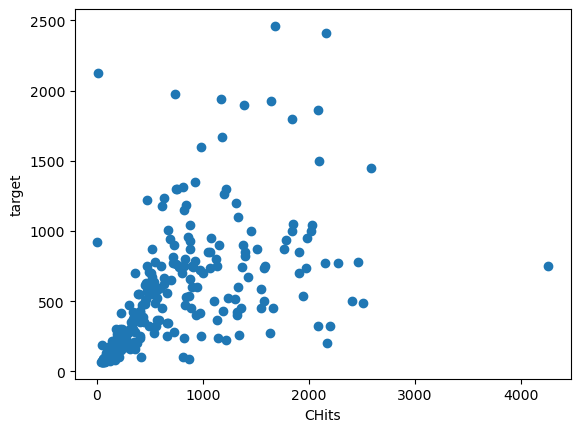

train: X.shape = (157, 16), y.shape = (157,)
validation: X.shape = (52, 16), y.shape = (52,)
test: X.shape = (54, 16), y.shape = (54,)
extras[0] = Annotation(0.553836, 0.954545, 'x[5] <= -1.828\nsquared_error = 72961.513\nsamples = 72\nvalue = 250.882')


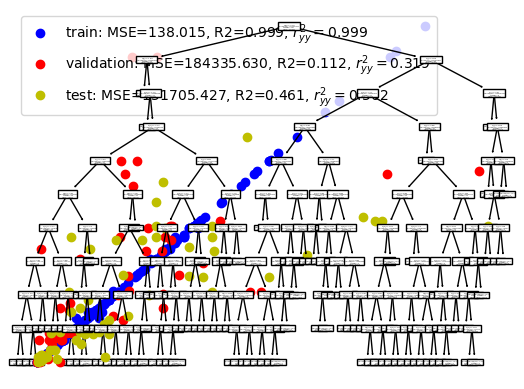

In [ ]:
# 20-depth Regression Tree

# Import and initial data plot
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import sklearn

from sklearn.tree import plot_tree
from sklearn.tree import DecisionTreeRegressor

hitters = pd.read_csv("hittersISLPDataAnalysis202627.csv")
X_pd = hitters.drop(columns=["Salary", "Unnamed: 0"])
numerics = ['int16', 'int32', 'int64', 'float16', 'float32', 'float64']
X_pd = X_pd.select_dtypes(include="number")
y_pd = hitters["Salary"]
print(f"X_pd.shape = {X_pd.shape}")
print(f"y_pd.shape = {y_pd.shape}")
print(f"[x for x in X_pd.columns] = {[x for x in X_pd.columns]}")

ix = 8
plt.plot(X_pd.iloc[:, ix], y_pd, 'o')
plt.xlabel(X_pd.columns[ix])
plt.ylabel('target')
plt.show()


# Split & Normalise
def split_dataset(D, ratio):
    X, y = D
    reshuffle = np.random.choice(len(X), len(X), replace=False)
    nratio = [int(np.floor(r * len(X))) for r in ratio]
    Xtrain, ytrain = [np.array([s[i] for i in reshuffle[:nratio[0]]]) for s in D]
    Xval, yval = [np.array([s[i] for i in reshuffle[nratio[0]:nratio[0] + nratio[1]]]) for s in D]
    Xtest, ytest = [np.array([s[i] for i in reshuffle[nratio[0] + nratio[1]:]]) for s in D]
    return (Xtrain, ytrain), (Xval, yval), (Xtest, ytest)

def normalise_features(X, y, means=None, stds=None):
    if means is None:
        means = np.mean(X, axis=0)
    if stds is None:
        stds = np.std(X, axis=0)
    return (X - means)/(1e-4 + stds), y, means, stds

raw_datasets = split_dataset((X_pd.to_numpy(dtype=float), y_pd.to_numpy(dtype=float)), (.6, .2))
train_X, train_y, means, stds = normalise_features(*raw_datasets[0])
val_X, val_y, _, _ = normalise_features(*raw_datasets[1], means, stds)
test_X, test_y, _, _ = normalise_features(*raw_datasets[2], means, stds)
datasets = [(train_X, train_y), (val_X, val_y), (test_X, test_y)]
data_names = ['train', 'validation', 'test']
for idata in range(len(data_names)):
    X, y = datasets[idata]
    print(f"{data_names[idata]}: X.shape = {X.shape}, y.shape = {y.shape}")


# Load & build decision tree
from sklearn.tree import plot_tree
from sklearn.tree import DecisionTreeRegressor

train, val, test = datasets
dt_diabetes = DecisionTreeRegressor(max_depth=10)
dt_diabetes.fit(train[0], train[1])
extras = plot_tree(dt_diabetes)
print(f"extras[0] = {extras[1]}")


# Evaluation Measures
def RSS(y, haty):
    return np.sum((y-haty) ** 2)

def MSE(y, haty):
    return RSS(y, haty)/len(y)

def TSS(y):
    return np.sum((y-np.mean(y)) ** 2)

def R2(y, haty):
    return 1 - RSS(y, haty)/TSS(y)

def rxy(x, y):
    a = (x-np.mean(x))@(y-np.mean(y))
    b = np.sqrt(TSS(x) * TSS(y))
    return a/b

data_colors= ['b', 'r', 'y']
for idata in range(len(data_names)):
    name = data_names[idata]
    X, y = datasets[idata]
    color = data_colors[idata]
    haty = dt_diabetes.predict(X)
    label = f'{name}: MSE={MSE(y, haty):.3f}, R2={R2(y, haty):.3f}, $r_{{yy}}^2=${rxy(y, haty)**2:.3f}'
    plt.plot(y, haty, 'o', color = color, label=label)
plt.legend()
plt.xlabel('y')
plt.ylabel('$\\hat y$')
plt.show()

### Q2

##### Train a shallow neural net to predict the salary of players in the `Hitters` dataset. Compare its predictions with those of the models trained and tested in Q1. Plot the true responses against the predictions for all models and report the corresponding test $MSE$ and the $R^2$ in the legend. Does the NN overfit the training set? Does changing the number of hidden units improve its performance?

**Hint:** You need to change the network architecture and the training objective (use `nn.MSELoss()`).  

In [ ]:
# Objective: Create a shallow neural network to predict the salary of players in the Hitters dataset using PyTorch. Compare predictions against Q1.
# Then: Plot response vs predictions and report the Mean Squared Error and R^2 in the legend. 
# Finally: Does the network overfit, and does changing the number of hidden neurons improve overall performance.